# Small model

## Imports

In [1]:
import numpy as np
from tvb.simulator.lab import *
from jansen_rit_FIC import wFICJansenRit
from jansen_rit_postFIC import pFICJansenRit
import matplotlib.pyplot as plt

## Parameters

In [3]:
your_y0_target = np.array([0.01])       # (default: 0.01)
your_eta = np.array([0.01])              # (default: 0.1 or 0.01)
your_tau_d = np.array([50])             # (default: 50)

# global coupling value (G)
gc_val = np.array([30])                 # (default: 30)
detORstoch = "det"  # 'stock' or 'det' to turn on the noise during tuning

## Connectivity

In [4]:
sample_centres = np.zeros((9,2))
sample_sc_weights = np.ones(8)
sample_sc_weights = np.diag(sample_sc_weights, 1) + np.diag(sample_sc_weights, -1)
sample_sc_lengths = sample_sc_weights*10
sample_rls = np.array([f"{i}" for i in range(-4, 4)])

s_conn = connectivity.Connectivity(
        weights = sample_sc_weights,
        tract_lengths= sample_sc_lengths
    )
s_conn.weights = s_conn.weights - s_conn.weights*np.eye(s_conn.weights.shape[0])
s_conn.weights = s_conn.scaled_weights(mode='tract')
s_conn.region_labels=sample_rls
s_conn.centres = sample_centres
s_conn.speed = np.array([3])
s_conn.configure()

## Utilities

In [5]:
def SigmoidJR(ts, sim):
    e0 = sim.model.nu_max
    v0 = sim.model.v0
    r0 = sim.model.r 
    return (2*e0) / (1 + np.exp(r0*(v0-ts)))

def find_closest_value(input_value, muy_dict, shift=1):
    # Find the index of the closest value in FP_y0 to the input_value
    if input_value <= 0.0189 or (input_value > 0.079 and input_value < 0.097) or input_value >= 0.125:
        reg = 'FP' 
    elif input_value > 0.0189 and input_value < 0.065:
        reg = 'SLC'
    elif input_value >= 0.097 and input_value < 0.125:
        reg = 'FLC'
    mu_arr, y0_arr = muy_dict[reg]
    mu_arr = np.array(mu_arr)
    y0_arr = np.array(y0_arr)
    if input_value > np.max(y0_arr) or input_value < np.min(y0_arr) :
        #print('y0 input value > max or < min of the y0 array: setting mu to closest available value')
        closest_index = np.argmin(np.abs(y0_arr - input_value))
    else:
        closest_index = np.argmin(np.abs(y0_arr - input_value))
    # Get the corresponding value from FP_mu using the index
    try: 
        corresponding_value = mu_arr[closest_index+shift]
    except:
        corresponding_value = mu_arr[closest_index]
    #print(f'y0:{input_value} on {reg} -------> mu: {numpy.round(corresponding_value, 4)} idx ={closest_index}  !!!')
    return np.round(corresponding_value, 4)

def get_init_conds(input_value, FP_y0, FP_y1, FP_y2, FP_y3, FP_y4, FP_y5, shift=5):
    # Find the index of the closest value in FP_y0 to the input_value
    closest_index = np.argmin(np.abs(FP_y0 - input_value))
    # Get the corresponding value from state variables using the index + the shift
    #print(f'y0:{input_value} -------> idx: {closest_index+shift} !!!')
    try: 
        corresponding_values = [FP_y0[closest_index+shift], FP_y1[closest_index+shift], FP_y2[closest_index+shift],
         FP_y3[closest_index+shift],FP_y4[closest_index+shift],FP_y5[closest_index+shift]]
    except:
        corresponding_values = [FP_y0[closest_index], FP_y1[closest_index], FP_y2[closest_index],
         FP_y3[closest_index],FP_y4[closest_index],FP_y5[closest_index]]
    return np.round(corresponding_values, 4)

## Simulation

#### Run function

In [6]:
def run_fic_sim(conn, gc_val, y0_target, eta, tau_d, integration="det", sim_length=8000):

    # Initial conditions
    mu_y0_dict = np.load("mu_y0_dict.npy", allow_pickle=True).item()
    mu_val = find_closest_value(y0_target, mu_y0_dict, 3)

    mu_values, y0s, y1s, y2s, y3s, y4s, y5s, _ = np.load("all_ys_vs_mu_array.npy", allow_pickle=True)

    init_y0 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[0], (1,1,s_conn.weights.shape[0],1))
    init_y1 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[1], (1,1,s_conn.weights.shape[0],1))
    init_y2 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[2], (1,1,s_conn.weights.shape[0],1))
    init_y3 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[3], (1,1,s_conn.weights.shape[0],1))
    init_y4 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[4], (1,1,s_conn.weights.shape[0],1))
    init_y5 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[5], (1,1,s_conn.weights.shape[0],1))
    init_wFIC = np.random.uniform(1,1, size=(1,1,s_conn.weights.shape[0],1))
    init_PSP = init_y1 - (init_wFIC * init_y2)
    init_y0d = init_y0.copy()
    init_y2d = init_y2.copy()
    fic_init_UNI =  np.stack([init_y0,init_y1,init_y2,init_y3,init_y4,init_y5,init_y0d, init_y2d, init_wFIC, init_PSP],axis = 1).squeeze(axis=2)

    # NM model
    jrm_fic = wFICJansenRit(
        eta = eta,
        y0_target = y0_target,
        tau_d = tau_d,
    )

    # integrator
    if integration == "det":
        integrator = integrators.HeunDeterministic(dt=0.1)
    if integration == "stoch":
        sigma = np.zeros(9)
        sigma[3] = 0.00000025
        integrator = integrators.HeunStochastic(dt=0.1, noise=noise.Additive(nsig=sigma))

    # simulator
    sim = simulator.Simulator(
        connectivity = conn,
        model = jrm_fic,
        coupling = coupling.SigmoidalJansenRit(a=gc_val, r=np.array([0.56])),
        integrator = integrator,
        monitors = [monitors.SubSample(period=1)],
        initial_conditions = fic_init_UNI,
        simulation_length = sim_length,
    )

    sim.model.mu = np.array([mu_val])
    sim.configure()

    # run simulation
    output = sim.run()

    # extract values
    ssamp  = output[0][1]
    PSP    = ssamp[:,0,:,0]
    y0_psp = ssamp[:,1,:,0]
    wFIC   = ssamp[:,2,:,0]

    return PSP, y0_psp, wFIC


def run_sim(conn, gc_val, y0_target, pFIC, integration="stoch", sim_length=8000):

    # Initial conditions
    mu_y0_dict = np.load("mu_y0_dict.npy", allow_pickle=True).item()
    mu_val = find_closest_value(y0_target, mu_y0_dict, 3)

    mu_values, y0s, y1s, y2s, y3s, y4s, y5s, _ = np.load("all_ys_vs_mu_array.npy", allow_pickle=True)

    init_y0 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[0], (1,1,s_conn.weights.shape[0],1))
    init_y1 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[1], (1,1,s_conn.weights.shape[0],1))
    init_y2 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[2], (1,1,s_conn.weights.shape[0],1))
    init_y3 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[3], (1,1,s_conn.weights.shape[0],1))
    init_y4 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[4], (1,1,s_conn.weights.shape[0],1))
    init_y5 = np.reshape(np.ones(s_conn.weights.shape[0]) * get_init_conds(your_y0_target, y0s, y1s, y2s, y3s, y4s, y5s, 0)[5], (1,1,s_conn.weights.shape[0],1))
    init_wFIC = np.random.uniform(1,1, size=(1,1,s_conn.weights.shape[0],1))
    init_PSP = init_y1 - (init_wFIC * init_y2)
    init_y0d = init_y0.copy()
    init_y2d = init_y2.copy()
    fic_init_UNI =  np.stack([init_y0,init_y1,init_y2,init_y3,init_y4,init_y5,init_y0d, init_y2d, init_wFIC, init_PSP],axis = 1).squeeze(axis=2)

    # NM model
    jrm_post = pFICJansenRit(
        pFIC = pFIC,
    )

    # integrator
    if integration == "det":
        integrator = integrators.HeunDeterministic(dt=0.1)
    if integration == "stoch":
        sigma = np.zeros(9)
        sigma[3] = 0.00000025
        integrator = integrators.HeunStochastic(dt=0.1, noise=noise.Additive(nsig=sigma))

    # simulator
    sim = simulator.Simulator(
        connectivity = conn,
        model = jrm_post,
        coupling = coupling.SigmoidalJansenRit(a=gc_val, r=np.array([0.56])),
        integrator = integrator,
        monitors = [monitors.SubSample(period=1)],
        initial_conditions = fic_init_UNI,
        simulation_length = sim_length,
    )

    sim.model.mu = np.array([mu_val])
    sim.configure()

    # run simulation
    output = sim.run()

    # extract values
    ssamp  = output[0][1]
    PSP    = ssamp[:,0,:,0]
    y0_psp = ssamp[:,1,:,0]
    wFIC   = ssamp[:,2,:,0]

    return PSP, y0_psp, wFIC

#### Run

In [7]:
print("Running fic tuning ...")
if your_y0_target <= 0.02 or your_y0_target > 0.095:
    print("Ok.... let's go!")
else:
    print("y0_target out of range")

fic_results = run_fic_sim(
    conn = s_conn,
    gc_val = gc_val,
    y0_target = your_y0_target,
    eta = your_eta,
    tau_d = your_tau_d,
    integration = "det",
    sim_length=80000
)

Running fic tuning ...
Ok.... let's go!
2025-08-21 08:38:35,296 - WARNING - tvb.simulator.integrators - random_state supplied for non-stochastic integration


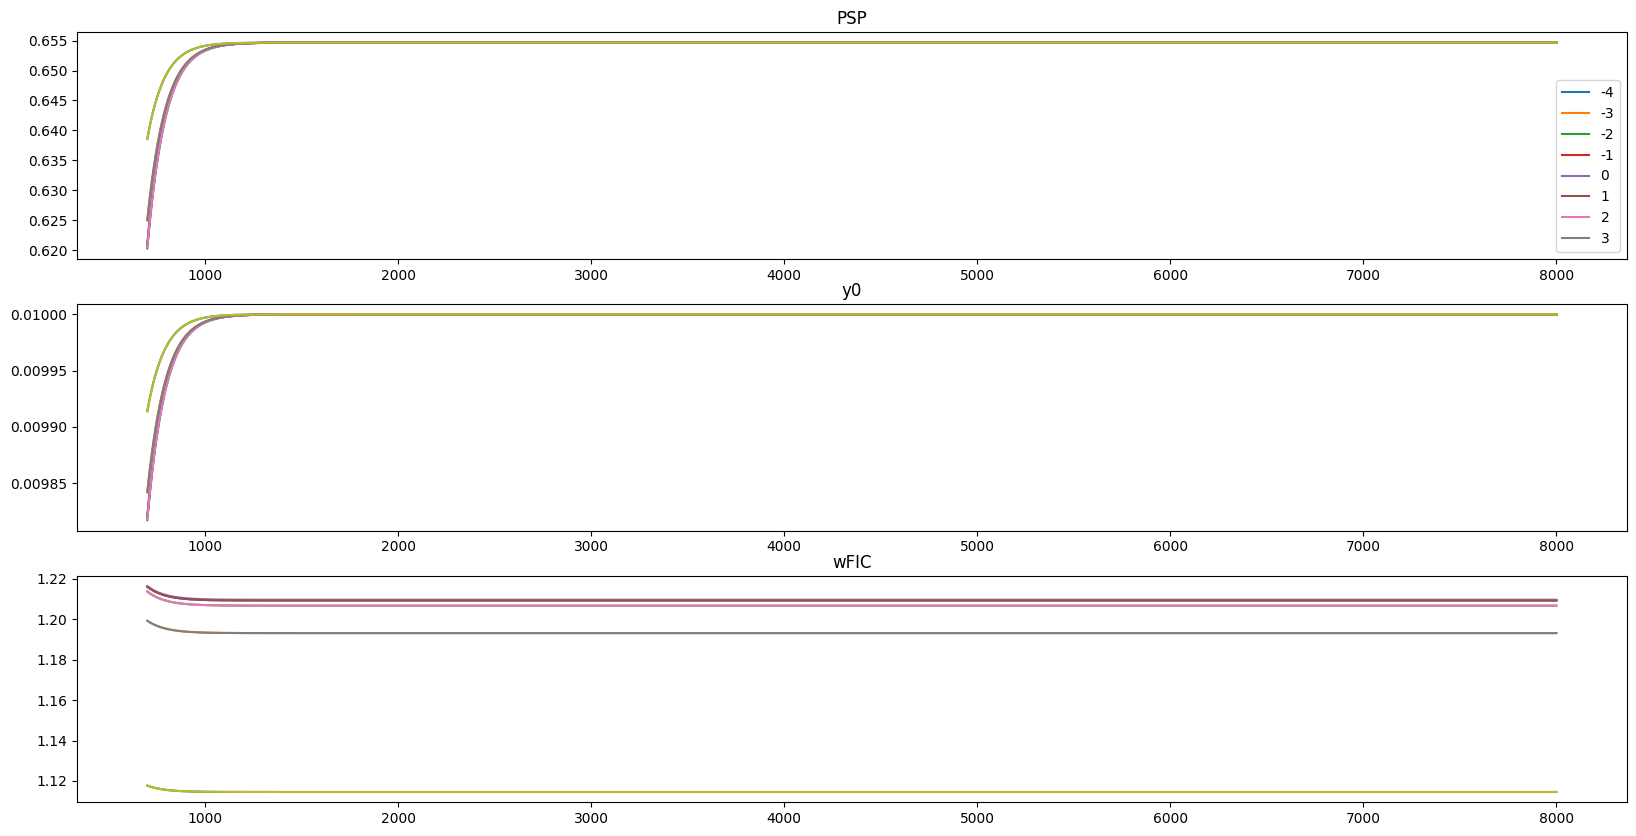

In [8]:
import matplotlib.pyplot as plt 

start = 7000

PSP, y0_psp, wFIC = fic_results
time = np.arange(PSP.shape[0])*0.1

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(20,10))

axs[0].plot(time[start:], PSP[start:])
axs[0].set_title("PSP")
axs[0].legend(s_conn.region_labels)

axs[1].plot(time[start:], y0_psp[start:])
axs[1].set_title("y0")

axs[2].plot(time[start:], wFIC[start:])
axs[2].set_title("wFIC")

plt.show()

In [8]:
print("Running fic model ...")
if your_y0_target <= 0.02 or your_y0_target > 0.095:
    print("Ok.... let's go!")
else:
    print("y0_target out of range")

pFIC = np.mean(wFIC[-100:], axis=0)

sim_results = run_sim(
    conn = s_conn,
    gc_val = gc_val,
    y0_target = your_y0_target,
    integration = "det",
    sim_length = 4000,
    pFIC = pFIC,
)

Running fic model ...
Ok.... let's go!


ValueError: Incorrect history sample shape (10, 9, 1), expected (7, 9, 1)

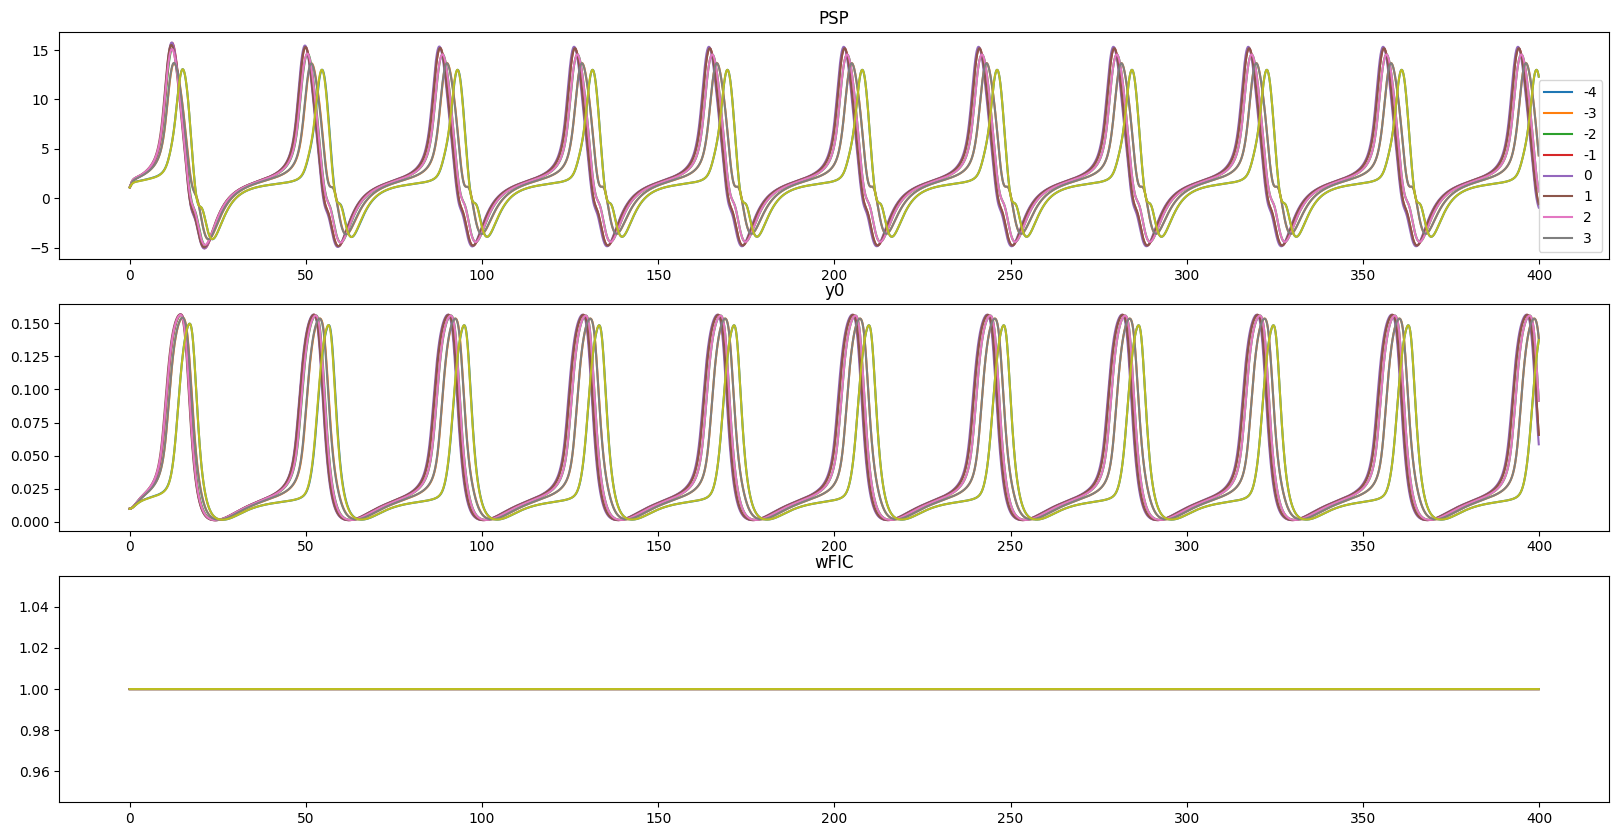

In [48]:
start = 0

PSP, y0_psp, wFIC = sim_results
time = np.arange(PSP.shape[0])*0.1

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(20,10))

axs[0].plot(time[start:], PSP[start:])
axs[0].set_title("PSP")
axs[0].legend(s_conn.region_labels)

axs[1].plot(time[start:], y0_psp[start:])
axs[1].set_title("y0")

axs[2].plot(time[start:], wFIC[start:])
axs[2].set_title("wFIC")

plt.show()

In [5]:
[(5,)*10]

[(5, 5, 5, 5, 5, 5, 5, 5, 5, 5)]

In [6]:
[(3,)*3 + (5,)*4 + (3,)*3]

[(3, 3, 3, 5, 5, 5, 5, 3, 3, 3)]